#Retail Inventory & Demand Analysis Using Python

Dataset Information
- Dataset Name: Retail Store Inventory Forecasting Dataset
- Source: Kaggle
- Dataset URL: https://www.kaggle.com/datasets/atomicd/retail-store-inventory-and-demand-forecasting
- Domain: Retail Analytics and Inventory Management
- File Format: CSV
- Dataset Size: 76,000 records and 16 columns
- Key Variables: Inventory Level, Units Sold, Units Ordered, Price, Discount, Competitor Pricing, Seasonality, and Demand
- Tools: Python, Pandas, NumPy, Matplotlib, Seaborn

##Project Objectives
The main objectives of this project are:
- Analyze inventory levels across different stores, products, categories, and regions.
- Identify high-demand and low-demand products to understand purchasing patterns.
- Evaluate sales performance based on units sold, product categories, and geographical regions.
- Examine the relationship between inventory levels, units sold, and customer demand.
- Analyze the impact of discounts, competitor pricing, promotions, and seasonal factors on product demand.
- Identify potential stock shortages and excess inventory to improve inventory management.
- Perform exploratory data analysis and statistical analysis using Python.
- Develop an interactive Power BI dashboard to present key performance indicators, business insights, and actionable recommendations.
- Provide data-driven recommendations to support inventory planning, demand management, and business decision-making.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = "https://raw.githubusercontent.com/Maathangi1412/FUTURE_DS_01/refs/heads/main/Sales_Dataset.csv"

df = pd.read_csv(url)

In [3]:
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [4]:
df.shape

(76000, 16)

In [5]:
df.columns

Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount',
       'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality',
       'Epidemic', 'Demand'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                76000 non-null  object 
 1   Store ID            76000 non-null  object 
 2   Product ID          76000 non-null  object 
 3   Category            76000 non-null  object 
 4   Region              76000 non-null  object 
 5   Inventory Level     76000 non-null  int64  
 6   Units Sold          76000 non-null  int64  
 7   Units Ordered       76000 non-null  int64  
 8   Price               76000 non-null  float64
 9   Discount            76000 non-null  int64  
 10  Weather Condition   76000 non-null  object 
 11  Promotion           76000 non-null  int64  
 12  Competitor Pricing  76000 non-null  float64
 13  Seasonality         76000 non-null  object 
 14  Epidemic            76000 non-null  int64  
 15  Demand              76000 non-null  int64  
dtypes: f

In [7]:
df.describe()

,Inventory Level,Units Sold,Units Ordered,Price,Discount,Promotion,Competitor Pricing,Epidemic,Demand
count,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000
mean,301.062842,88.827316,89.090645,67.726028,9.087039,0.328947,69.454029,0.200000,104.317158
std,226.510161,43.994525,162.404627,39.377899,7.475781,0.469834,40.943818,0.400003,46.964801
min,0.000000,0.000000,0.000000,4.740000,0.000000,0.000000,4.290000,0.000000,4.000000
25%,136.000000,58.000000,0.000000,31.997500,5.000000,0.000000,32.620000,0.000000,71.000000
50%,227.000000,84.000000,0.000000,64.500000,10.000000,0.000000,65.700000,0.000000,100.000000
75%,408.000000,114.000000,121.000000,95.830000,10.000000,1.000000,97.932500,0.000000,133.000000
max,2267.000000,426.000000,1616.000000,228.030000,25.000000,1.000000,261.220000,1.000000,430.000000


In [9]:
df.describe(include='object')

,Date,Store ID,Product ID,Category,Region,Weather Condition,Seasonality
count,76000,76000,76000,76000,76000,76000,76000
unique,760,5,20,5,4,4,4
top,2024-01-30,S001,P0001,Groceries,North,Cloudy,Winter
freq,100,15200,3800,30400,30400,24360,21000


In [10]:
categorical_columns = df.select_dtypes(include='object').columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


Date:
['2022-01-01' '2022-01-02' '2022-01-03' '2022-01-04' '2022-01-05'
 '2022-01-06' '2022-01-07' '2022-01-08' '2022-01-09' '2022-01-10'
 '2022-01-11' '2022-01-12' '2022-01-13' '2022-01-14' '2022-01-15'
 '2022-01-16' '2022-01-17' '2022-01-18' '2022-01-19' '2022-01-20'
 '2022-01-21' '2022-01-22' '2022-01-23' '2022-01-24' '2022-01-25'
 '2022-01-26' '2022-01-27' '2022-01-28' '2022-01-29' '2022-01-30'
 '2022-01-31' '2022-02-01' '2022-02-02' '2022-02-03' '2022-02-04'
 '2022-02-05' '2022-02-06' '2022-02-07' '2022-02-08' '2022-02-09'
 '2022-02-10' '2022-02-11' '2022-02-12' '2022-02-13' '2022-02-14'
 '2022-02-15' '2022-02-16' '2022-02-17' '2022-02-18' '2022-02-19'
 '2022-02-20' '2022-02-21' '2022-02-22' '2022-02-23' '2022-02-24'
 '2022-02-25' '2022-02-26' '2022-02-27' '2022-02-28' '2022-03-01'
 '2022-03-02' '2022-03-03' '2022-03-04' '2022-03-05' '2022-03-06'
 '2022-03-07' '2022-03-08' '2022-03-09' '2022-03-10' '2022-03-11'
 '2022-03-12' '2022-03-13' '2022-03-14' '2022-03-15' '2022-03-16'
 '2

In [11]:
for column in df.columns:
    print(column, ":", df[column].nunique())

Date : 760
Store ID : 5
Product ID : 20
Category : 5
Region : 4
Inventory Level : 1426
Units Sold : 330
Units Ordered : 996
Price : 15396
Discount : 6
Weather Condition : 4
Promotion : 2
Competitor Pricing : 15963
Seasonality : 4
Epidemic : 2
Demand : 340


In [12]:
print("Minimum Date:", df["Date"].min())
print("Maximum Date:", df["Date"].max())

Minimum Date: 2022-01-01
Maximum Date: 2024-01-30


In [13]:
print("Numerical Columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Columns:")
print(df.select_dtypes(include="object").columns.tolist())

Numerical Columns:
['Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Promotion', 'Competitor Pricing', 'Epidemic', 'Demand']

Categorical Columns:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Weather Condition', 'Seasonality']


In [14]:
df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)

Original Dataset Shape: (76000, 16)
Working Dataset Shape: (76000, 16)


In [15]:
missing_values = df_clean.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
Demand                0
dtype: int64


In [16]:
missing_percentage = (df_clean.isnull().sum() / len(df_clean)) * 100

print("Missing Value Percentage:")
print(missing_percentage.round(2))

Missing Value Percentage:
Date                  0.0
Store ID              0.0
Product ID            0.0
Category              0.0
Region                0.0
Inventory Level       0.0
Units Sold            0.0
Units Ordered         0.0
Price                 0.0
Discount              0.0
Weather Condition     0.0
Promotion             0.0
Competitor Pricing    0.0
Seasonality           0.0
Epidemic              0.0
Demand                0.0
dtype: float64


In [17]:
duplicate_count = df_clean.duplicated().sum()

print("Number of Duplicate Records:", duplicate_count)

Number of Duplicate Records: 0


In [18]:
duplicate_combinations = df_clean.duplicated(
    subset=["Date", "Store ID", "Product ID"]
).sum()

print("Duplicate Store-Product-Date Combinations:", duplicate_combinations)

Duplicate Store-Product-Date Combinations: 0


In [19]:
print("Column Data Types:")
print(df_clean.dtypes)

Column Data Types:
Date                   object
Store ID               object
Product ID             object
Category               object
Region                 object
Inventory Level         int64
Units Sold              int64
Units Ordered           int64
Price                 float64
Discount                int64
Weather Condition      object
Promotion               int64
Competitor Pricing    float64
Seasonality            object
Epidemic                int64
Demand                  int64
dtype: object


In [21]:
numerical_columns = df_clean.select_dtypes(include=np.number).columns

for column in numerical_columns:
    print(f"{column}: {(df_clean[column] < 0).sum()} negative values")

Inventory Level: 0 negative values
Units Sold: 0 negative values
Units Ordered: 0 negative values
Price: 0 negative values
Discount: 0 negative values
Promotion: 0 negative values
Competitor Pricing: 0 negative values
Epidemic: 0 negative values
Demand: 0 negative values


In [22]:
df_clean["Date"] = pd.to_datetime(df_clean["Date"], errors="coerce")

print(df_clean["Date"].dtype)

datetime64[ns]


In [23]:
invalid_dates = df_clean["Date"].isnull().sum()

print("Invalid Dates:", invalid_dates)

Invalid Dates: 0


In [24]:
df_clean["Year"] = df_clean["Date"].dt.year

df_clean["Month"] = df_clean["Date"].dt.month

df_clean["Day"] = df_clean["Date"].dt.day

df_clean[["Date", "Year", "Month", "Day"]].head()

,Date,Year,Month,Day
0,2022-01-01,2022,1,1
1,2022-01-01,2022,1,1
2,2022-01-01,2022,1,1
3,2022-01-01,2022,1,1
4,2022-01-01,2022,1,1


In [25]:
numerical_columns = df_clean.select_dtypes(include=np.number).columns

for column in numerical_columns:
    print(column, ":", df_clean[column].dtype)

Inventory Level : int64
Units Sold : int64
Units Ordered : int64
Price : float64
Discount : int64
Promotion : int64
Competitor Pricing : float64
Epidemic : int64
Demand : int64
Year : int32
Month : int32
Day : int32


In [26]:
categorical_columns = df_clean.select_dtypes(include="object").columns

print("Categorical Columns:")
print(categorical_columns.tolist())

Categorical Columns:
['Store ID', 'Product ID', 'Category', 'Region', 'Weather Condition', 'Seasonality']


In [27]:
print("Promotion Values:")
print(df_clean["Promotion"].value_counts(dropna=False))

print("\nEpidemic Values:")
print(df_clean["Epidemic"].value_counts(dropna=False))

Promotion Values:
Promotion
0    51000
1    25000
Name: count, dtype: int64

Epidemic Values:
Epidemic
0    60800
1    15200
Name: count, dtype: int64


In [28]:
df_clean.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,76000,2023-01-15 12:00:00,2022-01-01 00:00:00,2022-07-09 18:00:00,2023-01-15 12:00:00,2023-07-24 06:00:00,2024-01-30 00:00:00,NaN
Inventory Level,76000.0,301.062842,0.0,136.0,227.0,408.0,2267.0,226.510161
Units Sold,76000.0,88.827316,0.0,58.0,84.0,114.0,426.0,43.994525
Units Ordered,76000.0,89.090645,0.0,0.0,0.0,121.0,1616.0,162.404627
Price,76000.0,67.726028,4.74,31.9975,64.5,95.83,228.03,39.377899
Discount,76000.0,9.087039,0.0,5.0,10.0,10.0,25.0,7.475781
Promotion,76000.0,0.328947,0.0,0.0,0.0,1.0,1.0,0.469834
Competitor Pricing,76000.0,69.454029,4.29,32.62,65.7,97.9325,261.22,40.943818
Epidemic,76000.0,0.2,0.0,0.0,0.0,0.0,1.0,0.400003
Demand,76000.0,104.317158,4.0,71.0,100.0,133.0,430.0,46.964801


In [29]:
categorical_columns = df_clean.select_dtypes(include="object").columns

for column in categorical_columns:
    print(f"\n{column}")
    print(df_clean[column].value_counts(dropna=False))


Store ID
Store ID
S001    15200
S002    15200
S003    15200
S004    15200
S005    15200
Name: count, dtype: int64

Product ID
Product ID
P0001    3800
P0002    3800
P0003    3800
P0004    3800
P0005    3800
P0006    3800
P0007    3800
P0008    3800
P0009    3800
P0010    3800
P0011    3800
P0012    3800
P0013    3800
P0014    3800
P0015    3800
P0016    3800
P0017    3800
P0018    3800
P0019    3800
P0020    3800
Name: count, dtype: int64

Category
Category
Groceries      30400
Furniture      13680
Clothing       12160
Toys           10640
Electronics     9120
Name: count, dtype: int64

Region
Region
North    30400
South    15200
East     15200
West     15200
Name: count, dtype: int64

Weather Condition
Weather Condition
Cloudy    24360
Sunny     22980
Rainy     17500
Snowy     11160
Name: count, dtype: int64

Seasonality
Seasonality
Winter    21000
Spring    18400
Summer    18400
Autumn    18200
Name: count, dtype: int64


In [30]:
print("Promotion unique values:", df_clean["Promotion"].unique())

print("Epidemic unique values:", df_clean["Epidemic"].unique())

Promotion unique values: [0 1]
Epidemic unique values: [0 1]


In [31]:
# Identify text columns
categorical_columns = df_clean.select_dtypes(include="object").columns

# Remove leading and trailing spaces
for column in categorical_columns:
    df_clean[column] = df_clean[column].str.strip()

print("Unnecessary spaces removed successfully!")

Unnecessary spaces removed successfully!


In [32]:
for column in categorical_columns:
    print(f"\n{column}:")
    print(df_clean[column].unique())


Store ID:
['S001' 'S002' 'S003' 'S004' 'S005']

Product ID:
['P0001' 'P0002' 'P0003' 'P0004' 'P0005' 'P0006' 'P0007' 'P0008' 'P0009'
 'P0010' 'P0011' 'P0012' 'P0013' 'P0014' 'P0015' 'P0016' 'P0017' 'P0018'
 'P0019' 'P0020']

Category:
['Electronics' 'Clothing' 'Groceries' 'Toys' 'Furniture']

Region:
['North' 'South' 'East' 'West']

Weather Condition:
['Snowy' 'Cloudy' 'Sunny' 'Rainy']

Seasonality:
['Winter' 'Spring' 'Summer' 'Autumn']


In [33]:
# Count missing values in each column
missing_values = df_clean.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
Demand                0
Year                  0
Month                 0
Day                   0
dtype: int64


In [34]:
missing_percentage = (
    df_clean.isnull().sum() / len(df_clean)
) * 100

print("Missing Value Percentage:")
print(missing_percentage.round(2))

Missing Value Percentage:
Date                  0.0
Store ID              0.0
Product ID            0.0
Category              0.0
Region                0.0
Inventory Level       0.0
Units Sold            0.0
Units Ordered         0.0
Price                 0.0
Discount              0.0
Weather Condition     0.0
Promotion             0.0
Competitor Pricing    0.0
Seasonality           0.0
Epidemic              0.0
Demand                0.0
Year                  0.0
Month                 0.0
Day                   0.0
dtype: float64


In [35]:
# Count duplicate records
duplicate_count = df_clean.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


In [36]:
df_clean = df_clean.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df_clean.shape)

Dataset Shape After Removing Duplicates: (76000, 19)


In [37]:
print("Dataset Shape:", df_clean.shape)

Dataset Shape: (76000, 19)


In [38]:
print(df_clean.isnull().sum())

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
Demand                0
Year                  0
Month                 0
Day                   0
dtype: int64


In [39]:
# Select numerical columns
numerical_columns = df_clean.select_dtypes(include=np.number).columns

# Display statistical summary
df_clean[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Inventory Level,76000.0,301.062842,226.510161,0.00,136.0000,227.0,408.0000,2267.00
Units Sold,76000.0,88.827316,43.994525,0.00,58.0000,84.0,114.0000,426.00
Units Ordered,76000.0,89.090645,162.404627,0.00,0.0000,0.0,121.0000,1616.00
Price,76000.0,67.726028,39.377899,4.74,31.9975,64.5,95.8300,228.03
Discount,76000.0,9.087039,7.475781,0.00,5.0000,10.0,10.0000,25.00
Promotion,76000.0,0.328947,0.469834,0.00,0.0000,0.0,1.0000,1.00
Competitor Pricing,76000.0,69.454029,40.943818,4.29,32.6200,65.7,97.9325,261.22
Epidemic,76000.0,0.200000,0.400003,0.00,0.0000,0.0,0.0000,1.00
Demand,76000.0,104.317158,46.964801,4.00,71.0000,100.0,133.0000,430.00
Year,76000.0,2022.559211,0.570479,2022.00,2022.0000,2023.0,2023.0000,2024.00


In [40]:
business_columns = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Price",
    "Discount",
    "Competitor Pricing",
    "Demand"
]

for column in business_columns:
    print(
        column,
        ":",
        (df_clean[column] < 0).sum(),
        "negative values"
    )

Inventory Level : 0 negative values
Units Sold : 0 negative values
Units Ordered : 0 negative values
Price : 0 negative values
Discount : 0 negative values
Competitor Pricing : 0 negative values
Demand : 0 negative values


In [41]:
print("Unique Discount Values:")
print(sorted(df_clean["Discount"].unique()))

Unique Discount Values:
[np.int64(0), np.int64(5), np.int64(10), np.int64(15), np.int64(20), np.int64(25)]


In [42]:
business_columns = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Price",
    "Discount",
    "Competitor Pricing",
    "Demand"
]

for column in business_columns:

    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]

    print(f"\n{column}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Outlier Count:", len(outliers))


Inventory Level
Q1: 136.0
Q3: 408.0
IQR: 272.0
Lower Bound: -272.0
Upper Bound: 816.0
Outlier Count: 2759

Units Sold
Q1: 58.0
Q3: 114.0
IQR: 56.0
Lower Bound: -26.0
Upper Bound: 198.0
Outlier Count: 1411

Units Ordered
Q1: 0.0
Q3: 121.0
IQR: 121.0
Lower Bound: -181.5
Upper Bound: 302.5
Outlier Count: 7524

Price
Q1: 31.9975
Q3: 95.83
IQR: 63.832499999999996
Lower Bound: -63.75125
Upper Bound: 191.57875
Outlier Count: 70

Discount
Q1: 5.0
Q3: 10.0
IQR: 5.0
Lower Bound: -2.5
Upper Bound: 17.5
Outlier Count: 12413

Competitor Pricing
Q1: 32.62
Q3: 97.9325
IQR: 65.3125
Lower Bound: -65.34875
Upper Bound: 195.90125
Outlier Count: 185

Demand
Q1: 71.0
Q3: 133.0
IQR: 62.0
Lower Bound: -22.0
Upper Bound: 226.0
Outlier Count: 986


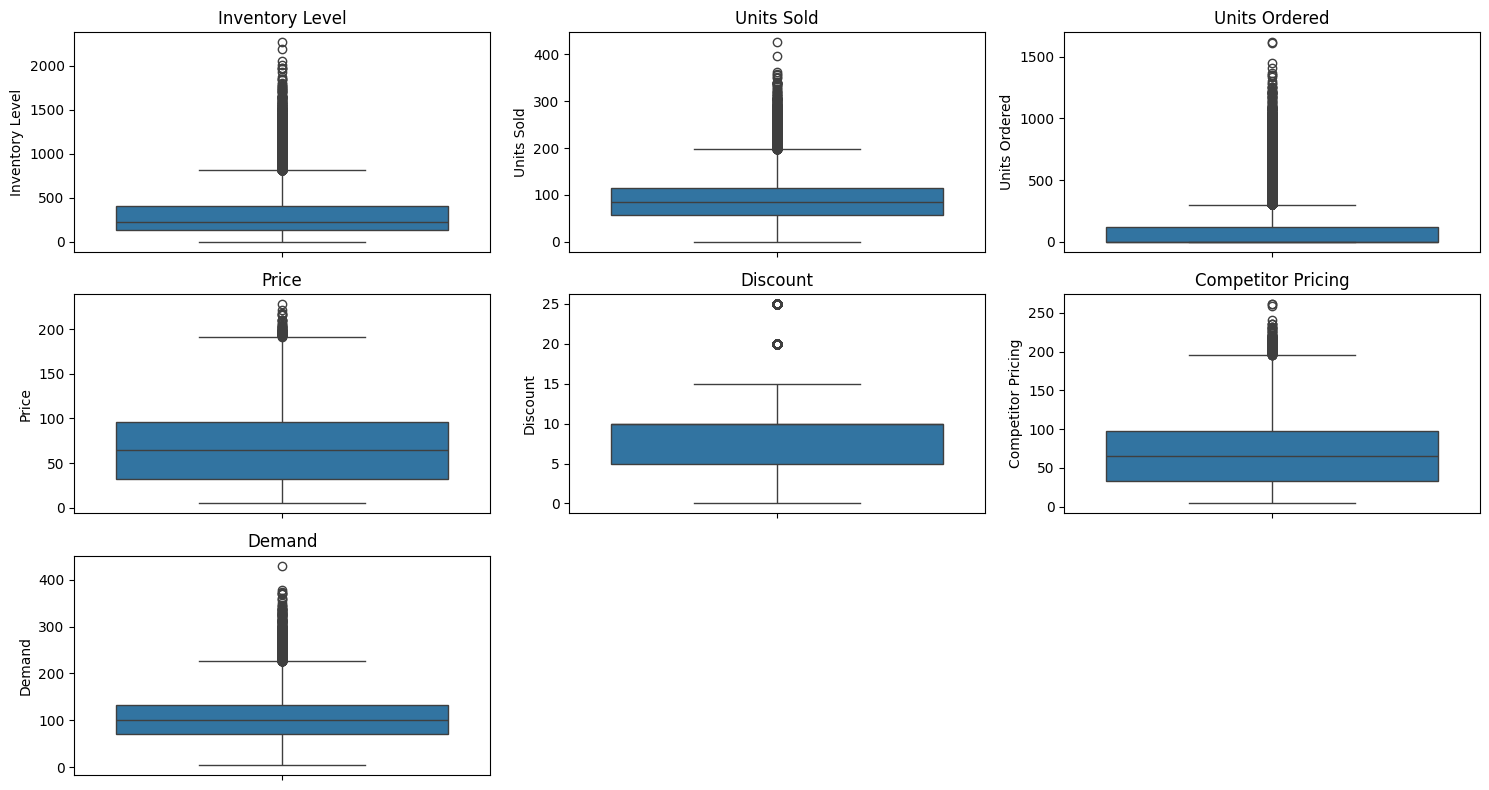

In [43]:
plt.figure(figsize=(15, 8))

for i, column in enumerate(business_columns, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df_clean[column])
    plt.title(column)

plt.tight_layout()
plt.show()

In [44]:
print("Final Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate Records:")
print(df_clean.duplicated().sum())

Final Dataset Shape: (76000, 19)

Missing Values:
0

Duplicate Records:
0


In [45]:
# Calculate gross revenue
df_clean["Gross Revenue"] = (
    df_clean["Units Sold"] * df_clean["Price"]
)

# Calculate discount amount
df_clean["Discount Amount"] = (
    df_clean["Gross Revenue"] * df_clean["Discount"] / 100
)

# Calculate net revenue
df_clean["Net Revenue"] = (
    df_clean["Gross Revenue"] - df_clean["Discount Amount"]
)

df_clean[[
    "Units Sold", "Price", "Discount",
    "Gross Revenue", "Discount Amount", "Net Revenue"
]].head()

,Units Sold,Price,Discount,Gross Revenue,Discount Amount,Net Revenue
0,102,72.72,5,7417.44,370.872,7046.568
1,117,80.16,15,9378.72,1406.808,7971.912
2,114,62.94,10,7175.16,717.516,6457.644
3,45,87.63,10,3943.35,394.335,3549.015
4,65,54.41,0,3536.65,0.000,3536.650


In [46]:
# Calculate inventory gap
df_clean["Inventory Gap"] = (
    df_clean["Inventory Level"] - df_clean["Demand"]
)

# Calculate potential stock shortfall
df_clean["Potential Shortfall"] = (
    df_clean["Demand"] - df_clean["Inventory Level"]
).clip(lower=0)

# Calculate inventory surplus
df_clean["Inventory Surplus"] = (
    df_clean["Inventory Level"] - df_clean["Demand"]
).clip(lower=0)

df_clean[[
    "Inventory Level", "Demand",
    "Inventory Gap", "Potential Shortfall", "Inventory Surplus"
]].head()

,Inventory Level,Demand,Inventory Gap,Potential Shortfall,Inventory Surplus
0,195,115,80,0,80
1,117,229,-112,112,0
2,247,157,90,0,90
3,139,52,87,0,87
4,152,59,93,0,93


In [47]:
df_clean["Inventory Status"] = np.where(
    df_clean["Inventory Gap"] < 0,
    "Potential Shortage",
    np.where(
        df_clean["Inventory Gap"] == 0,
        "Inventory Balanced",
        "Inventory Surplus"
    )
)

print(df_clean["Inventory Status"].value_counts())

Inventory Status
Inventory Surplus     65405
Potential Shortage    10394
Inventory Balanced      201
Name: count, dtype: int64


In [48]:
df_clean["Month Name"] = df_clean["Date"].dt.month_name()

print(df_clean[["Date", "Year", "Month", "Month Name"]].head())

        Date  Year  Month Month Name
0 2022-01-01  2022      1    January
1 2022-01-01  2022      1    January
2 2022-01-01  2022      1    January
3 2022-01-01  2022      1    January
4 2022-01-01  2022      1    January


In [49]:
print("Updated Dataset Shape:", df_clean.shape)

df_clean.head()

Updated Dataset Shape: (76000, 27)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,...,Month,Day,Gross Revenue,Discount Amount,Net Revenue,Inventory Gap,Potential Shortfall,Inventory Surplus,Inventory Status,Month Name
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,...,1,1,7417.44,370.872,7046.568,80,0,80,Inventory Surplus,January
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,...,1,1,9378.72,1406.808,7971.912,-112,112,0,Potential Shortage,January
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,...,1,1,7175.16,717.516,6457.644,90,0,90,Inventory Surplus,January
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,...,1,1,3943.35,394.335,3549.015,87,0,87,Inventory Surplus,January
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,...,1,1,3536.65,0.000,3536.650,93,0,93,Inventory Surplus,January


In [50]:
total_revenue = df_clean["Net Revenue"].sum()
total_units_sold = df_clean["Units Sold"].sum()
total_demand = df_clean["Demand"].sum()
average_price = df_clean["Price"].mean()
average_discount = df_clean["Discount"].mean()
total_records = len(df_clean)

print("OVERALL BUSINESS PERFORMANCE")
print("--------------------------------")
print("Total Net Revenue:", round(total_revenue, 2))
print("Total Units Sold:", total_units_sold)
print("Total Demand:", total_demand)
print("Average Product Price:", round(average_price, 2))
print("Average Discount (%):", round(average_discount, 2))
print("Total Records:", total_records)

OVERALL BUSINESS PERFORMANCE
--------------------------------
Total Net Revenue: 412590589.82
Total Units Sold: 6750876
Total Demand: 7928104
Average Product Price: 67.73
Average Discount (%): 9.09
Total Records: 76000


In [51]:
total_inventory = df_clean["Inventory Level"].sum()

potential_shortage_records = (
    df_clean["Inventory Status"] == "Potential Shortage"
).sum()

surplus_records = (
    df_clean["Inventory Status"] == "Inventory Surplus"
).sum()

balanced_records = (
    df_clean["Inventory Status"] == "Inventory Balanced"
).sum()

print("INVENTORY PERFORMANCE")
print("----------------------")
print("Total Inventory:", total_inventory)
print("Potential Shortage Records:", potential_shortage_records)
print("Inventory Surplus Records:", surplus_records)
print("Balanced Inventory Records:", balanced_records)

INVENTORY PERFORMANCE
----------------------
Total Inventory: 22880776
Potential Shortage Records: 10394
Inventory Surplus Records: 65405
Balanced Inventory Records: 201


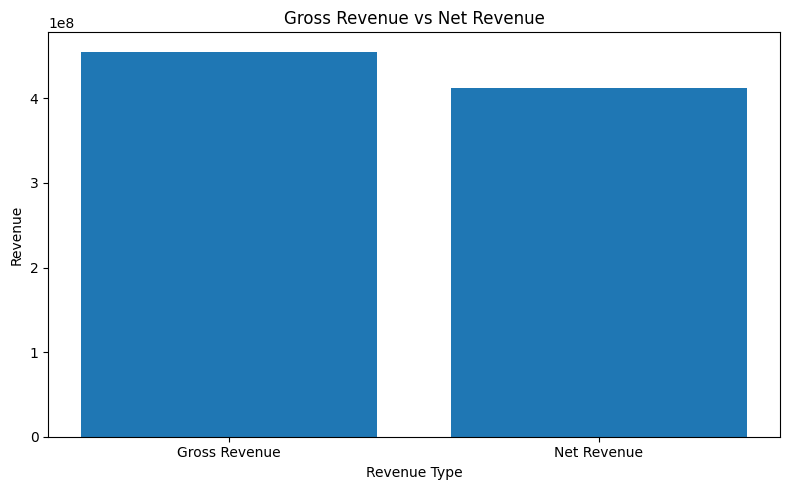

In [52]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["Gross Revenue", "Net Revenue"],
    [
        df_clean["Gross Revenue"].sum(),
        df_clean["Net Revenue"].sum()
    ]
)

plt.title("Gross Revenue vs Net Revenue")
plt.ylabel("Revenue")
plt.xlabel("Revenue Type")
plt.tight_layout()
plt.show()

In [53]:
monthly_revenue = (
    df_clean.groupby(["Year", "Month"])["Net Revenue"]
    .sum()
    .reset_index()
)

monthly_revenue.head()

,Year,Month,Net Revenue
0,2022,1,1.762094e+07
1,2022,2,1.704631e+07
2,2022,3,1.852041e+07
3,2022,4,1.569041e+07
4,2022,5,1.171124e+07


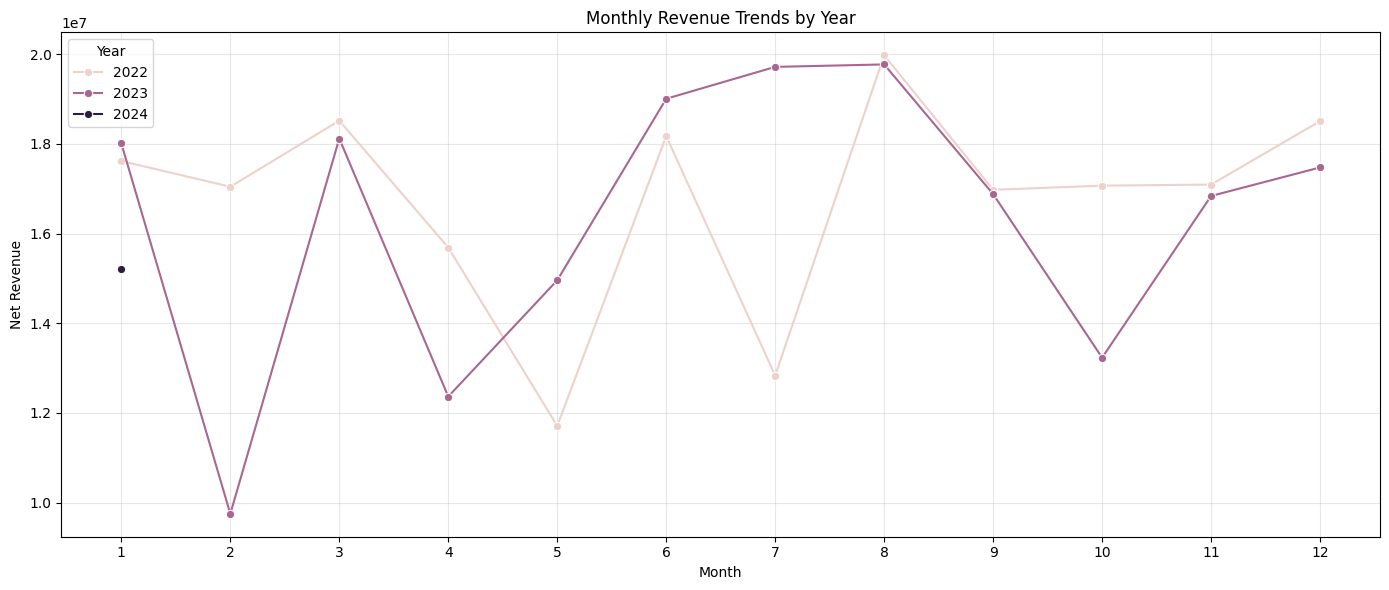

In [54]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_revenue,
    x="Month",
    y="Net Revenue",
    hue="Year",
    marker="o"
)

plt.title("Monthly Revenue Trends by Year")
plt.xlabel("Month")
plt.ylabel("Net Revenue")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [55]:
highest_month = monthly_revenue.loc[
    monthly_revenue["Net Revenue"].idxmax()
]

lowest_month = monthly_revenue.loc[
    monthly_revenue["Net Revenue"].idxmin()
]

print("Highest Revenue Month:")
print(highest_month)

print("\nLowest Revenue Month:")
print(lowest_month)

Highest Revenue Month:
Year           2.022000e+03
Month          8.000000e+00
Net Revenue    1.997949e+07
Name: 7, dtype: float64

Lowest Revenue Month:
Year           2.023000e+03
Month          2.000000e+00
Net Revenue    9.751030e+06
Name: 13, dtype: float64


In [56]:
yearly_revenue = (
    df_clean.groupby("Year")["Net Revenue"]
    .sum()
    .reset_index()
)

yearly_revenue

,Year,Net Revenue
0,2022,2.012313e+08
1,2023,1.961494e+08
2,2024,1.520993e+07


In [57]:
yearly_revenue["Revenue Growth (%)"] = (
    yearly_revenue["Net Revenue"].pct_change() * 100
)

yearly_revenue["Revenue Growth (%)"] = (
    yearly_revenue["Revenue Growth (%)"].round(2)
)

yearly_revenue

,Year,Net Revenue,Revenue Growth (%)
0,2022,2.012313e+08,NaN
1,2023,1.961494e+08,-2.53
2,2024,1.520993e+07,-92.25


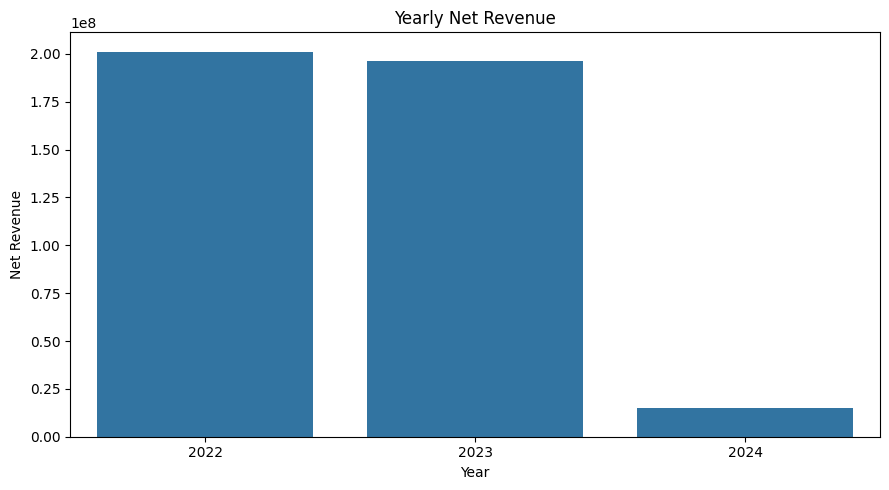

In [58]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=yearly_revenue,
    x="Year",
    y="Net Revenue"
)

plt.title("Yearly Net Revenue")
plt.xlabel("Year")
plt.ylabel("Net Revenue")
plt.tight_layout()
plt.show()

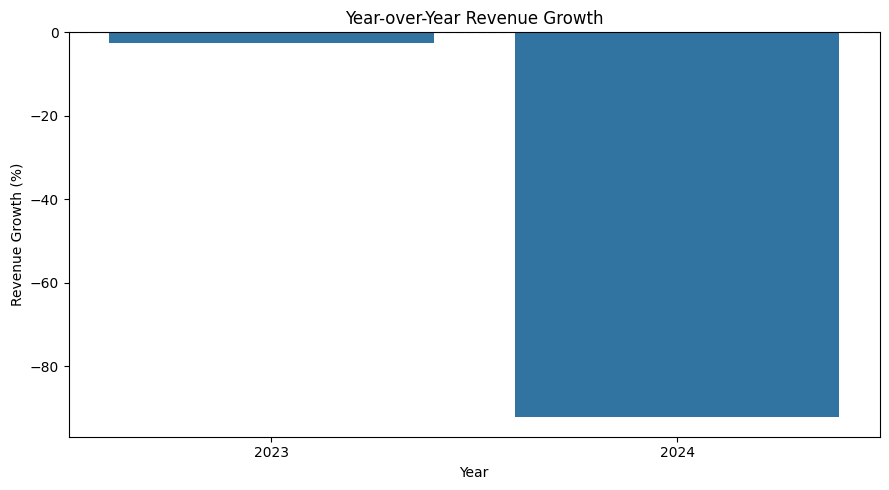

In [59]:
growth_data = yearly_revenue.dropna(
    subset=["Revenue Growth (%)"]
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=growth_data,
    x="Year",
    y="Revenue Growth (%)"
)

plt.title("Year-over-Year Revenue Growth")
plt.xlabel("Year")
plt.ylabel("Revenue Growth (%)")
plt.axhline(0, linestyle="--")
plt.tight_layout()
plt.show()

In [60]:
category_analysis = (
    df_clean.groupby("Category")
    .agg(
        Total_Revenue=("Net Revenue", "sum"),
        Total_Units_Sold=("Units Sold", "sum"),
        Total_Demand=("Demand", "sum"),
        Average_Price=("Price", "mean"),
        Average_Discount=("Discount", "mean")
    )
    .reset_index()
)

category_analysis = category_analysis.sort_values(
    by="Total_Revenue",
    ascending=False
)

category_analysis.round(2)

,Category,Total_Revenue,Total_Units_Sold,Total_Demand,Average_Price,Average_Discount
3,Groceries,1.529578e+08,3127335,3677684,51.66,9.12
2,Furniture,1.008930e+08,880654,1006590,121.51,9.01
0,Clothing,7.725332e+07,1150873,1369456,71.52,9.05
1,Electronics,5.983031e+07,757335,889036,83.17,9.06
4,Toys,2.165611e+07,834679,985338,26.91,9.18


In [61]:
category_analysis["Revenue Contribution (%)"] = (
    category_analysis["Total_Revenue"] /
    category_analysis["Total_Revenue"].sum()
) * 100

category_analysis["Revenue Contribution (%)"] = (
    category_analysis["Revenue Contribution (%)"].round(2)
)

category_analysis

,Category,Total_Revenue,Total_Units_Sold,Total_Demand,Average_Price,Average_Discount,Revenue Contribution (%)
3,Groceries,1.529578e+08,3127335,3677684,51.657799,9.116118,37.07
2,Furniture,1.008930e+08,880654,1006590,121.507112,9.005482,24.45
0,Clothing,7.725332e+07,1150873,1369456,71.519470,9.048109,18.72
1,Electronics,5.983031e+07,757335,889036,83.172102,9.055373,14.50
4,Toys,2.165611e+07,834679,985338,26.913289,9.180451,5.25


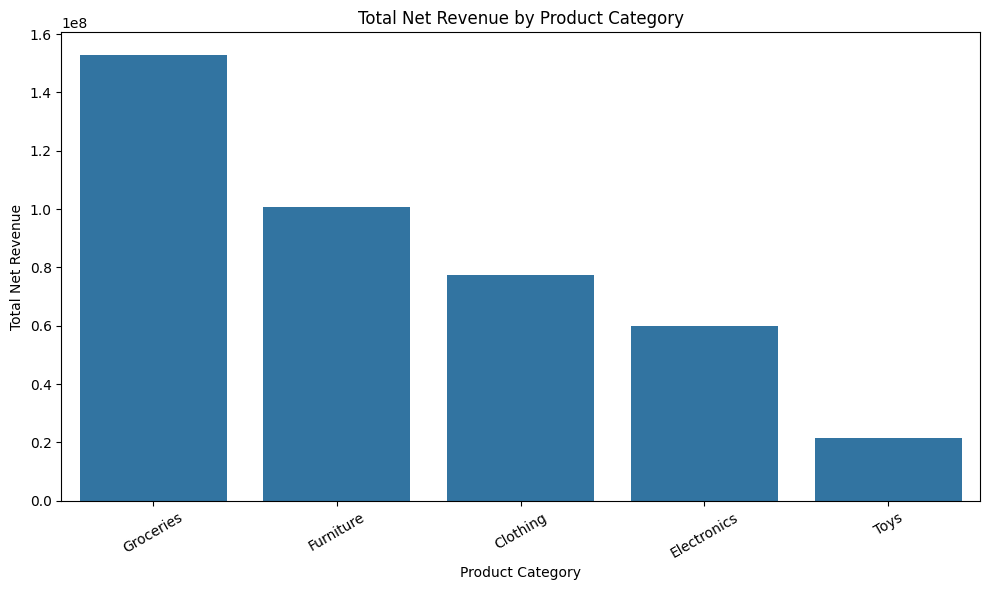

In [62]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Revenue"
)

plt.title("Total Net Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Net Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

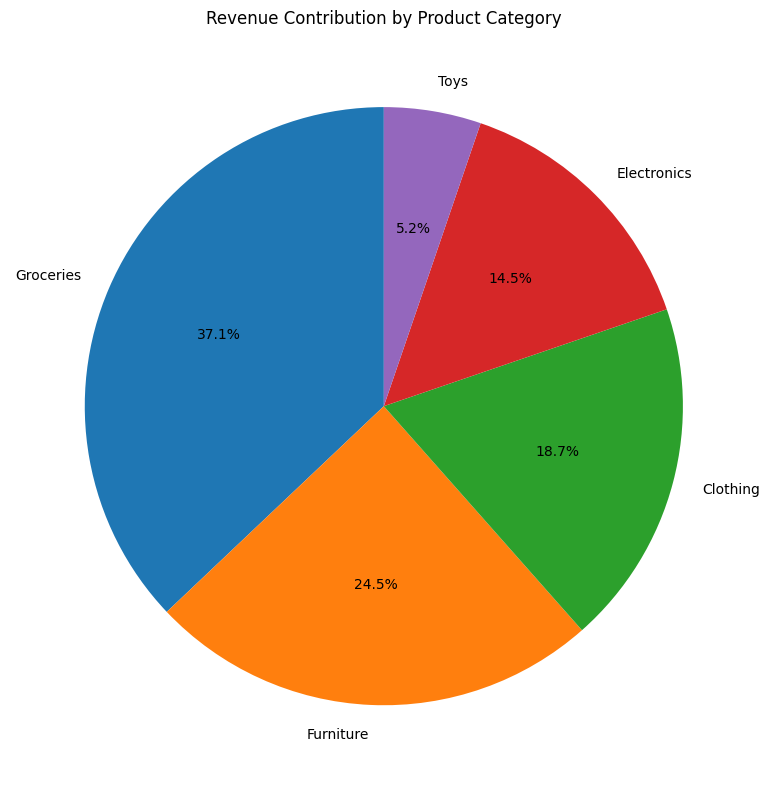

In [63]:
plt.figure(figsize=(8, 8))

plt.pie(
    category_analysis["Total_Revenue"],
    labels=category_analysis["Category"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Contribution by Product Category")
plt.tight_layout()
plt.show()

In [64]:
highest_category = category_analysis.iloc[0]
lowest_category = category_analysis.iloc[-1]

print("Highest Revenue Category:")
print(highest_category)

print("\nLowest Revenue Category:")
print(lowest_category)

Highest Revenue Category:
Category                         Groceries
Total_Revenue               152957810.2115
Total_Units_Sold                   3127335
Total_Demand                       3677684
Average_Price                    51.657799
Average_Discount                  9.116118
Revenue Contribution (%)             37.07
Name: 3, dtype: object

Lowest Revenue Category:
Category                            Toys
Total_Revenue               21656107.505
Total_Units_Sold                  834679
Total_Demand                      985338
Average_Price                  26.913289
Average_Discount                9.180451
Revenue Contribution (%)            5.25
Name: 4, dtype: object


In [65]:
product_analysis = (
    df_clean.groupby("Product ID")
    .agg(
        Total_Revenue=("Net Revenue", "sum"),
        Total_Units_Sold=("Units Sold", "sum"),
        Total_Demand=("Demand", "sum"),
        Average_Price=("Price", "mean"),
        Average_Inventory=("Inventory Level", "mean")
    )
    .reset_index()
)

product_analysis = product_analysis.sort_values(
    by="Total_Revenue",
    ascending=False
)

product_analysis.round(2)

,Product ID,Total_Revenue,Total_Units_Sold,Total_Demand,Average_Price,Average_Inventory
13,P0014,33539574.30,317397,364335,118.60,339.90
10,P0011,30442709.76,332883,382766,99.62,345.63
8,P0009,29520640.77,376771,450324,83.05,272.30
11,P0012,25471183.76,296256,347215,93.20,289.90
18,P0019,24113464.86,313209,371954,86.72,212.49
2,P0003,23839876.81,341531,395182,76.36,310.26
19,P0020,22804058.36,277961,320847,90.75,283.48
15,P0016,21629356.81,326718,382874,72.66,289.91
9,P0010,20881464.29,357299,422064,66.47,310.55
14,P0015,20476093.03,335443,389468,63.75,340.98


In [66]:
top_5_products = product_analysis.head(5)

top_5_products

,Product ID,Total_Revenue,Total_Units_Sold,Total_Demand,Average_Price,Average_Inventory
13,P0014,3.353957e+07,317397,364335,118.598295,339.902895
10,P0011,3.044271e+07,332883,382766,99.616218,345.631053
8,P0009,2.952064e+07,376771,450324,83.047739,272.303684
11,P0012,2.547118e+07,296256,347215,93.203937,289.895789
18,P0019,2.411346e+07,313209,371954,86.723679,212.485526


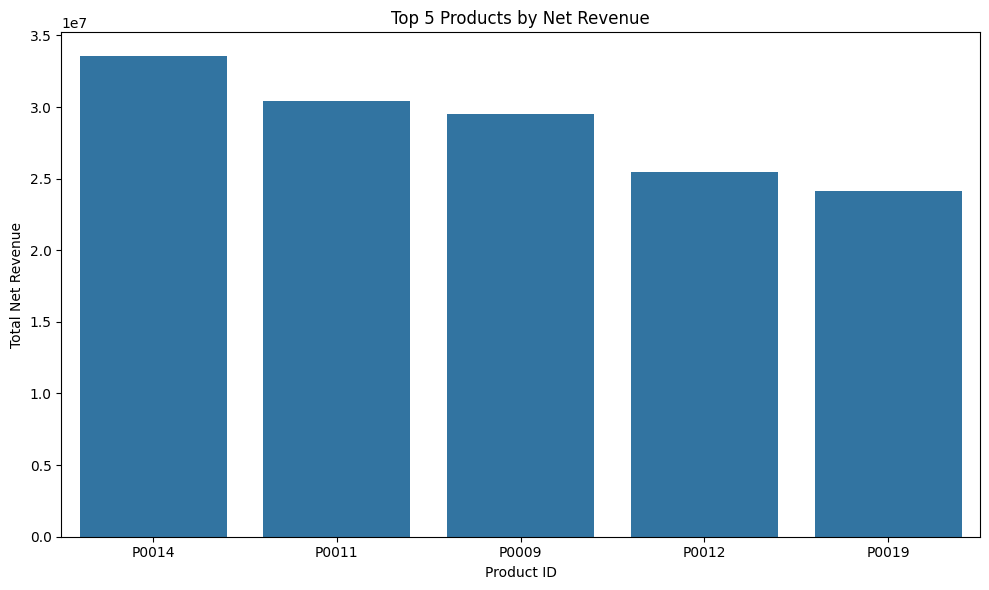

In [67]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_5_products,
    x="Product ID",
    y="Total_Revenue"
)

plt.title("Top 5 Products by Net Revenue")
plt.xlabel("Product ID")
plt.ylabel("Total Net Revenue")
plt.tight_layout()
plt.show()

In [68]:
bottom_5_products = product_analysis.tail(5)

bottom_5_products

,Product ID,Total_Revenue,Total_Units_Sold,Total_Demand,Average_Price,Average_Inventory
5,P0006,1.553627e+07,344589,409345,46.914603,283.058421
3,P0004,1.530041e+07,377627,438505,45.307184,320.350000
1,P0002,1.485310e+07,359355,425853,42.719934,285.830789
6,P0007,1.297319e+07,379709,437089,35.674368,466.860000
0,P0001,1.267224e+07,356814,416447,37.220403,331.758684


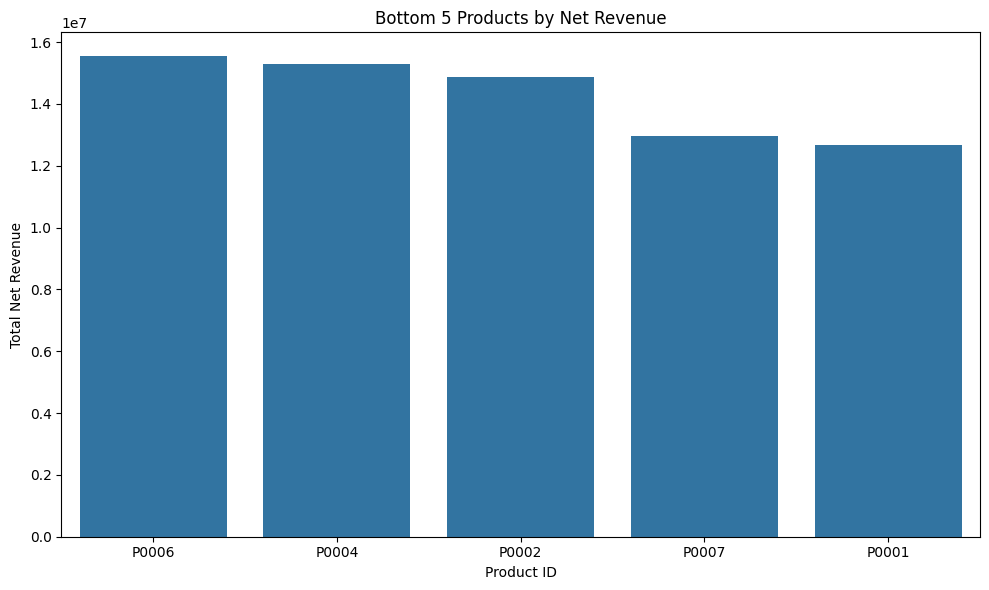

In [69]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=bottom_5_products,
    x="Product ID",
    y="Total_Revenue"
)

plt.title("Bottom 5 Products by Net Revenue")
plt.xlabel("Product ID")
plt.ylabel("Total Net Revenue")
plt.tight_layout()
plt.show()

In [70]:
highest_selling_product = product_analysis.sort_values(
    by="Total_Units_Sold",
    ascending=False
).iloc[0]

print("Highest-Selling Product:")
print(highest_selling_product)

Highest-Selling Product:
Product ID                   P0007
Total_Revenue        12973185.7235
Total_Units_Sold            379709
Total_Demand                437089
Average_Price            35.674368
Average_Inventory           466.86
Name: 6, dtype: object


In [71]:
region_analysis = (
    df_clean.groupby("Region")
    .agg(
        Total_Revenue=("Net Revenue", "sum"),
        Total_Units_Sold=("Units Sold", "sum"),
        Total_Demand=("Demand", "sum"),
        Average_Price=("Price", "mean"),
        Average_Discount=("Discount", "mean")
    )
    .reset_index()
)

region_analysis = region_analysis.sort_values(
    by="Total_Revenue",
    ascending=False
)

region_analysis.round(2)

,Region,Total_Revenue,Total_Units_Sold,Total_Demand,Average_Price,Average_Discount
1,North,1.541444e+08,2680946,3154658,63.36,9.08
0,East,8.925563e+07,1375613,1618324,70.09,9.08
3,West,8.559825e+07,1308191,1529651,77.41,9.09
2,South,8.359233e+07,1386126,1625471,64.40,9.10


In [72]:
region_analysis["Revenue Contribution (%)"] = (
    region_analysis["Total_Revenue"] /
    region_analysis["Total_Revenue"].sum()
) * 100

region_analysis["Revenue Contribution (%)"] = (
    region_analysis["Revenue Contribution (%)"].round(2)
)

region_analysis

,Region,Total_Revenue,Total_Units_Sold,Total_Demand,Average_Price,Average_Discount,Revenue Contribution (%)
1,North,1.541444e+08,2680946,3154658,63.362098,9.081908,37.36
0,East,8.925563e+07,1375613,1618324,70.092303,9.083882,21.63
3,West,8.559825e+07,1308191,1529651,77.412568,9.085855,20.75
2,South,8.359233e+07,1386126,1625471,64.401070,9.101645,20.26


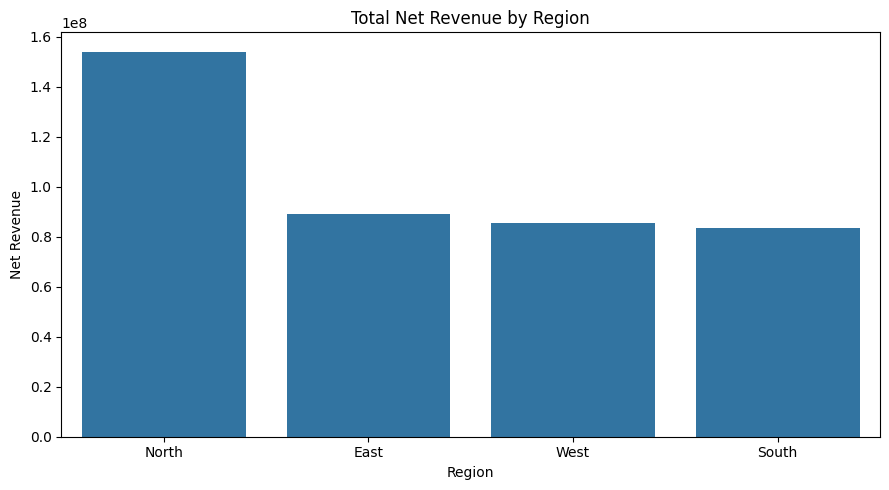

In [73]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=region_analysis,
    x="Region",
    y="Total_Revenue"
)

plt.title("Total Net Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Net Revenue")
plt.tight_layout()
plt.show()

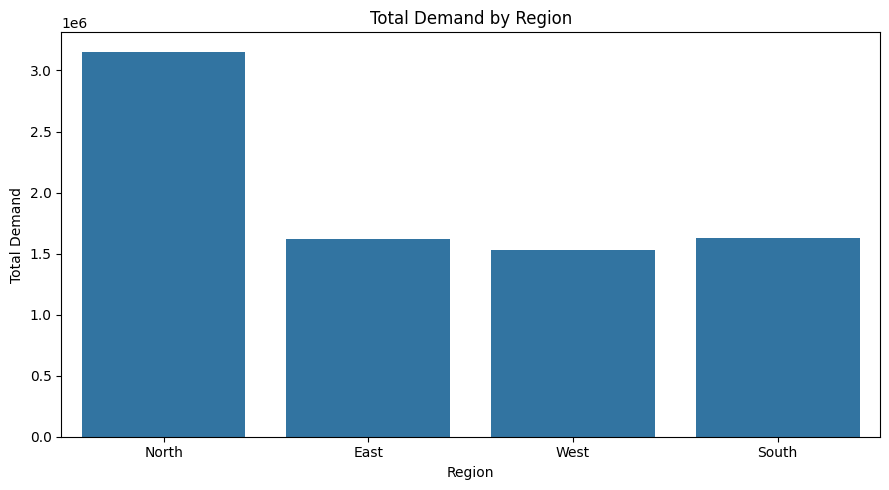

In [74]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=region_analysis,
    x="Region",
    y="Total_Demand"
)

plt.title("Total Demand by Region")
plt.xlabel("Region")
plt.ylabel("Total Demand")
plt.tight_layout()
plt.show()

In [75]:
best_region = region_analysis.iloc[0]
lowest_region = region_analysis.iloc[-1]

print("Highest Revenue Region:")
print(best_region)

print("\nLowest Revenue Region:")
print(lowest_region)

Highest Revenue Region:
Region                               North
Total_Revenue               154144375.7705
Total_Units_Sold                   2680946
Total_Demand                       3154658
Average_Price                    63.362098
Average_Discount                  9.081908
Revenue Contribution (%)             37.36
Name: 1, dtype: object

Lowest Revenue Region:
Region                             South
Total_Revenue               83592333.877
Total_Units_Sold                 1386126
Total_Demand                     1625471
Average_Price                   64.40107
Average_Discount                9.101645
Revenue Contribution (%)           20.26
Name: 2, dtype: object


In [76]:
store_analysis = (
    df_clean.groupby("Store ID")
    .agg(
        Total_Revenue=("Net Revenue", "sum"),
        Total_Units_Sold=("Units Sold", "sum"),
        Total_Demand=("Demand", "sum"),
        Average_Inventory=("Inventory Level", "mean"),
        Average_Discount=("Discount", "mean")
    )
    .reset_index()
)

store_analysis = store_analysis.sort_values(
    by="Total_Revenue",
    ascending=False
)

store_analysis.round(2)

,Store ID,Total_Revenue,Total_Units_Sold,Total_Demand,Average_Inventory,Average_Discount
2,S003,89255625.46,1375613,1618324,321.99,9.08
3,S004,85598254.71,1308191,1529651,293.24,9.09
1,S002,83592333.88,1386126,1625471,332.01,9.10
0,S001,81555358.44,1318134,1547573,277.66,9.04
4,S005,72589017.34,1362812,1607085,280.40,9.13


In [77]:
store_analysis["Revenue Contribution (%)"] = (
    store_analysis["Total_Revenue"] /
    store_analysis["Total_Revenue"].sum()
) * 100

store_analysis["Revenue Contribution (%)"] = (
    store_analysis["Revenue Contribution (%)"].round(2)
)

store_analysis

,Store ID,Total_Revenue,Total_Units_Sold,Total_Demand,Average_Inventory,Average_Discount,Revenue Contribution (%)
2,S003,8.925563e+07,1375613,1618324,321.993026,9.083882,21.63
3,S004,8.559825e+07,1308191,1529651,293.244211,9.085855,20.75
1,S002,8.359233e+07,1386126,1625471,332.014737,9.101645,20.26
0,S001,8.155536e+07,1318134,1547573,277.657368,9.038158,19.77
4,S005,7.258902e+07,1362812,1607085,280.404868,9.125658,17.59


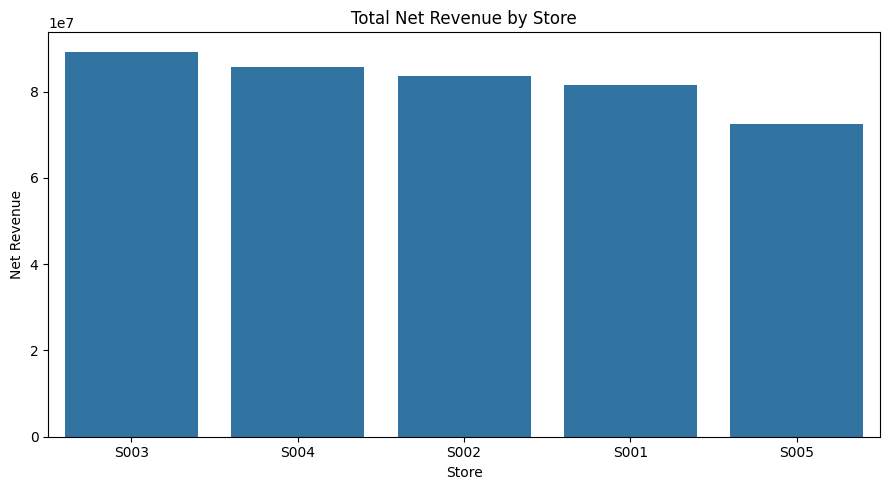

In [78]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=store_analysis,
    x="Store ID",
    y="Total_Revenue"
)

plt.title("Total Net Revenue by Store")
plt.xlabel("Store")
plt.ylabel("Net Revenue")
plt.tight_layout()
plt.show()

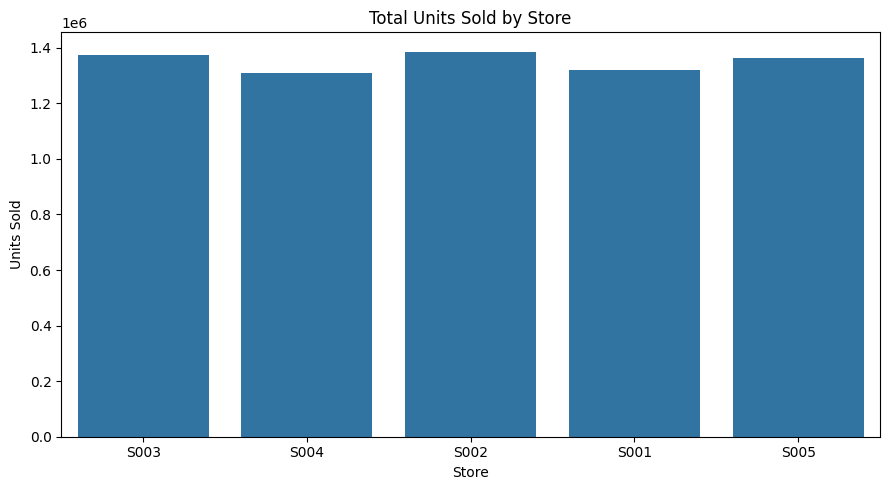

In [79]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=store_analysis,
    x="Store ID",
    y="Total_Units_Sold"
)

plt.title("Total Units Sold by Store")
plt.xlabel("Store")
plt.ylabel("Units Sold")
plt.tight_layout()
plt.show()

In [80]:
best_store = store_analysis.iloc[0]
lowest_store = store_analysis.iloc[-1]

print("Highest Revenue Store:")
print(best_store)

print("\nLowest Revenue Store:")
print(lowest_store)

Highest Revenue Store:
Store ID                            S003
Total_Revenue               89255625.465
Total_Units_Sold                 1375613
Total_Demand                     1618324
Average_Inventory             321.993026
Average_Discount                9.083882
Revenue Contribution (%)           21.63
Name: 2, dtype: object

Lowest Revenue Store:
Store ID                             S005
Total_Revenue               72589017.3355
Total_Units_Sold                  1362812
Total_Demand                      1607085
Average_Inventory              280.404868
Average_Discount                 9.125658
Revenue Contribution (%)            17.59
Name: 4, dtype: object


In [81]:
inventory_status = df_clean["Inventory Status"].value_counts()

print("Inventory Status Distribution:")
print(inventory_status)

print("\nInventory Status Percentage:")
print(
    (df_clean["Inventory Status"].value_counts(normalize=True) * 100)
    .round(2)
)

Inventory Status Distribution:
Inventory Status
Inventory Surplus     65405
Potential Shortage    10394
Inventory Balanced      201
Name: count, dtype: int64

Inventory Status Percentage:
Inventory Status
Inventory Surplus     86.06
Potential Shortage    13.68
Inventory Balanced     0.26
Name: proportion, dtype: float64


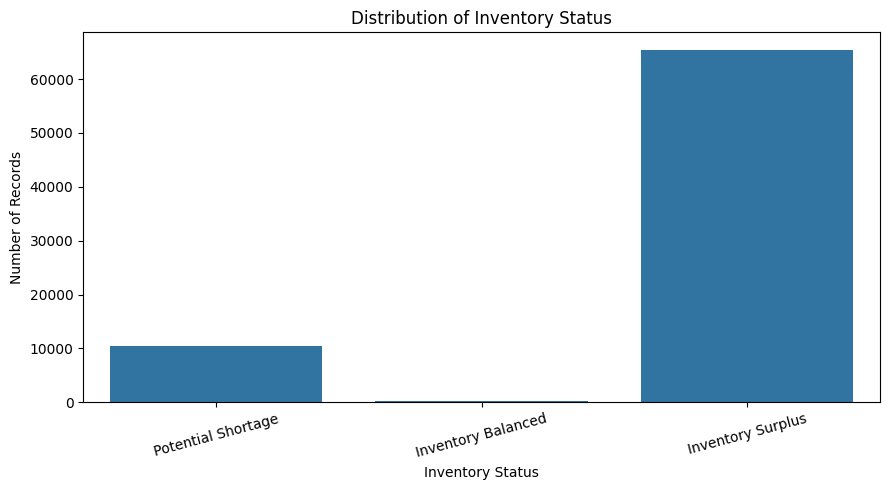

In [82]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x="Inventory Status",
    order=[
        "Potential Shortage",
        "Inventory Balanced",
        "Inventory Surplus"
    ]
)

plt.title("Distribution of Inventory Status")
plt.xlabel("Inventory Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [83]:
inventory_demand_analysis = (
    df_clean.groupby("Category")
    .agg(
        Average_Inventory=("Inventory Level", "mean"),
        Average_Demand=("Demand", "mean"),
        Average_Units_Sold=("Units Sold", "mean"),
        Total_Potential_Shortfall=("Potential Shortfall", "sum")
    )
    .reset_index()
)

inventory_demand_analysis.round(2)

,Category,Average_Inventory,Average_Demand,Average_Units_Sold,Total_Potential_Shortfall
0,Clothing,282.10,112.62,94.64,100926
1,Electronics,289.26,97.48,83.04,53034
2,Furniture,250.07,73.58,64.38,35448
3,Groceries,360.31,120.98,102.87,222394
4,Toys,229.11,92.61,78.45,64146


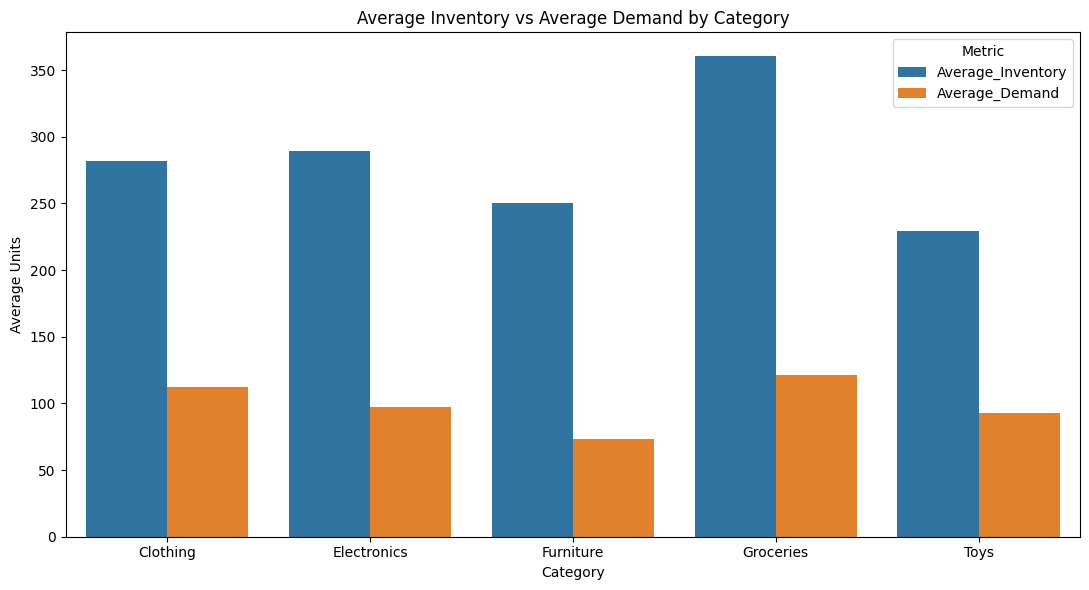

In [84]:
inventory_demand_plot = inventory_demand_analysis.melt(
    id_vars="Category",
    value_vars=["Average_Inventory", "Average_Demand"],
    var_name="Metric",
    value_name="Average_Value"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=inventory_demand_plot,
    x="Category",
    y="Average_Value",
    hue="Metric"
)

plt.title("Average Inventory vs Average Demand by Category")
plt.xlabel("Category")
plt.ylabel("Average Units")
plt.tight_layout()
plt.show()

In [85]:
shortfall_analysis = (
    df_clean.groupby("Product ID")
    ["Potential Shortfall"]
    .sum()
    .reset_index()
    .sort_values(
        by="Potential Shortfall",
        ascending=False
    )
)

print("Top 5 Products by Cumulative Potential Shortfall:")
print(shortfall_analysis.head(5))

Top 5 Products by Cumulative Potential Shortfall:
   Product ID  Potential Shortfall
7       P0008                43554
17      P0018                36213
8       P0009                34354
9       P0010                31060
1       P0002                29030


In [86]:
season_analysis = (
    df_clean.groupby("Seasonality")
    .agg(
        Total_Demand=("Demand", "sum"),
        Average_Demand=("Demand", "mean"),
        Total_Units_Sold=("Units Sold", "sum"),
        Average_Inventory=("Inventory Level", "mean")
    )
    .reset_index()
    .sort_values(by="Total_Demand", ascending=False)
)

season_analysis.round(2)

,Seasonality,Total_Demand,Average_Demand,Total_Units_Sold,Average_Inventory
3,Winter,2171530,103.41,1843181,299.43
2,Summer,2076539,112.86,1761945,320.58
0,Autumn,1882298,103.42,1610020,297.50
1,Spring,1797737,97.70,1535730,286.94


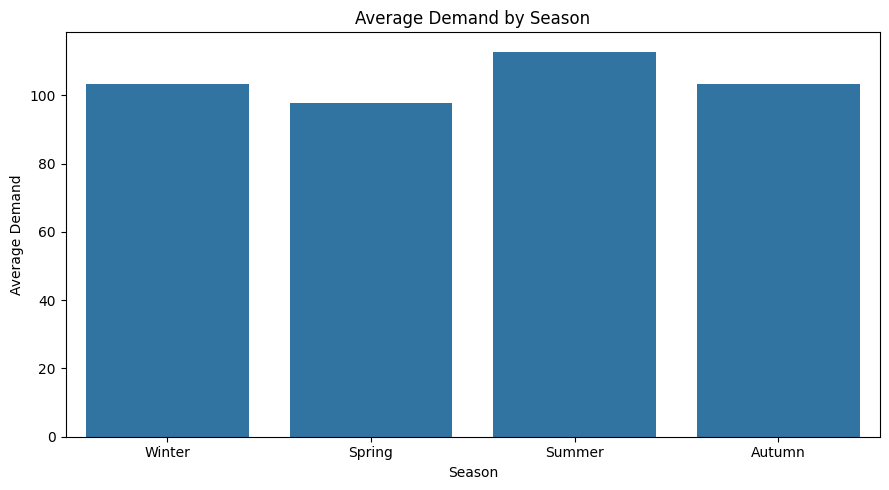

In [87]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=season_analysis,
    x="Seasonality",
    y="Average_Demand",
    order=["Winter", "Spring", "Summer", "Autumn"]
)

plt.title("Average Demand by Season")
plt.xlabel("Season")
plt.ylabel("Average Demand")
plt.tight_layout()
plt.show()

In [88]:
monthly_demand = (
    df_clean.groupby("Month")
    .agg(
        Average_Demand=("Demand", "mean"),
        Total_Demand=("Demand", "sum"),
        Total_Units_Sold=("Units Sold", "sum")
    )
    .reset_index()
)

monthly_demand.round(2)

,Month,Average_Demand,Total_Demand,Total_Units_Sold
0,1,106.04,975568,821964
1,2,92.88,520142,444355
2,3,113.61,704406,600243
3,4,92.82,556900,476978
4,5,86.52,536431,458509
5,6,117.35,704076,595826
6,7,101.56,629682,533552
7,8,119.80,742781,632567
8,9,107.43,644589,553157
9,10,95.56,592455,505501


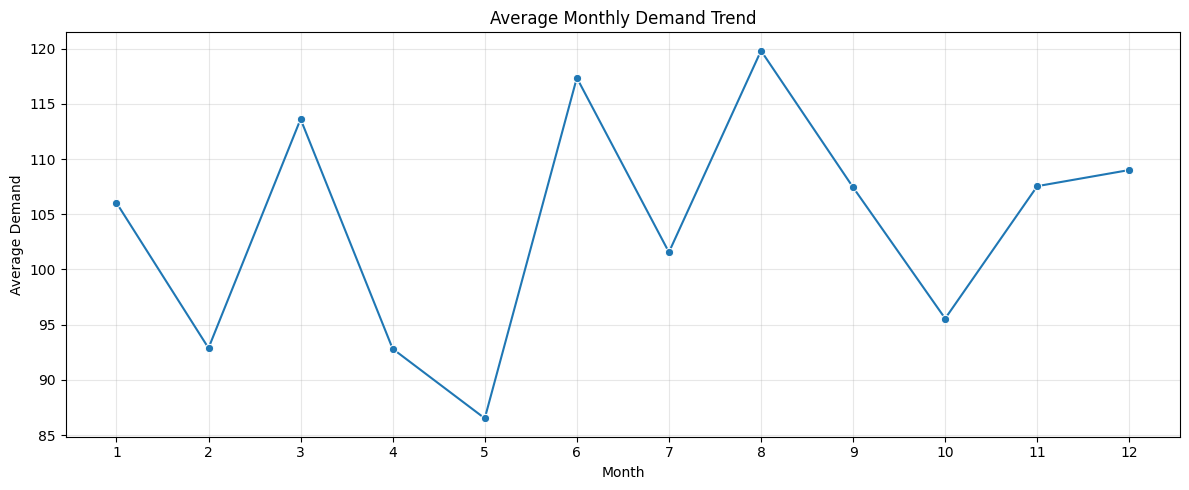

In [89]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_demand,
    x="Month",
    y="Average_Demand",
    marker="o"
)

plt.title("Average Monthly Demand Trend")
plt.xlabel("Month")
plt.ylabel("Average Demand")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [90]:
highest_demand_season = season_analysis.loc[
    season_analysis["Average_Demand"].idxmax()
]

lowest_demand_season = season_analysis.loc[
    season_analysis["Average_Demand"].idxmin()
]

print("Highest Average Demand Season:")
print(highest_demand_season)

print("\nLowest Average Demand Season:")
print(lowest_demand_season)

Highest Average Demand Season:
Seasonality              Summer
Total_Demand            2076539
Average_Demand        112.85538
Total_Units_Sold        1761945
Average_Inventory    320.578533
Name: 2, dtype: object

Lowest Average Demand Season:
Seasonality              Spring
Total_Demand            1797737
Average_Demand        97.703098
Total_Units_Sold        1535730
Average_Inventory    286.940598
Name: 1, dtype: object


In [91]:
promotion_analysis = (
    df_clean.groupby("Promotion")
    .agg(
        Total_Units_Sold=("Units Sold", "sum"),
        Average_Units_Sold=("Units Sold", "mean"),
        Average_Demand=("Demand", "mean"),
        Total_Revenue=("Net Revenue", "sum"),
        Average_Discount=("Discount", "mean")
    )
    .reset_index()
)

promotion_analysis.round(2)

,Promotion,Total_Units_Sold,Average_Units_Sold,Average_Demand,Total_Revenue,Average_Discount
0,0,4173499,81.83,95.03,2.720829e+08,4.98
1,1,2577377,103.10,123.27,1.405077e+08,17.46


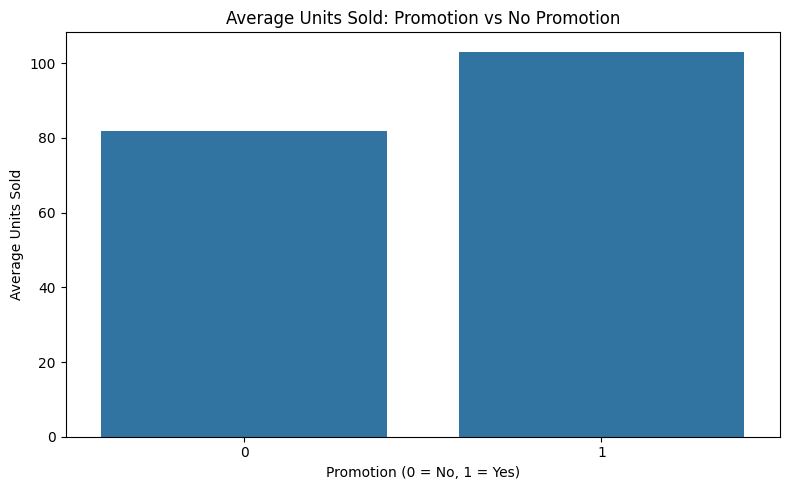

In [92]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=promotion_analysis,
    x="Promotion",
    y="Average_Units_Sold"
)

plt.title("Average Units Sold: Promotion vs No Promotion")
plt.xlabel("Promotion (0 = No, 1 = Yes)")
plt.ylabel("Average Units Sold")
plt.tight_layout()
plt.show()

In [93]:
discount_analysis = (
    df_clean.groupby("Discount")
    .agg(
        Total_Revenue=("Net Revenue", "sum"),
        Average_Revenue=("Net Revenue", "mean"),
        Average_Units_Sold=("Units Sold", "mean"),
        Average_Demand=("Demand", "mean")
    )
    .reset_index()
)

discount_analysis.round(2)

,Discount,Total_Revenue,Average_Revenue,Average_Units_Sold,Average_Demand
0,0,1.012555e+08,5912.38,81.57,94.75
1,5,8.941051e+07,5284.93,81.69,94.94
2,10,1.234384e+08,5298.24,87.66,102.77
3,15,3.700570e+07,5925.65,102.88,123.58
4,20,3.282744e+07,5302.45,103.77,124.07
5,25,2.865311e+07,4605.13,103.59,122.97


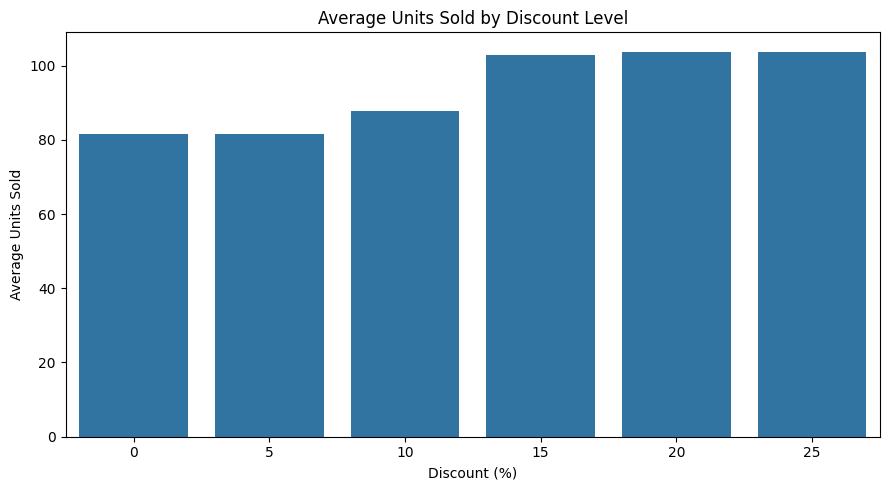

In [94]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=discount_analysis,
    x="Discount",
    y="Average_Units_Sold"
)

plt.title("Average Units Sold by Discount Level")
plt.xlabel("Discount (%)")
plt.ylabel("Average Units Sold")
plt.tight_layout()
plt.show()

In [95]:
df_clean["Price Difference"] = (
    df_clean["Price"] - df_clean["Competitor Pricing"]
)

df_clean["Price Position"] = np.where(
    df_clean["Price Difference"] > 0,
    "Priced Above Competitor",
    np.where(
        df_clean["Price Difference"] < 0,
        "Priced Below Competitor",
        "Same Price"
    )
)

competitor_analysis = (
    df_clean.groupby("Price Position")
    .agg(
        Record_Count=("Product ID", "count"),
        Average_Units_Sold=("Units Sold", "mean"),
        Average_Demand=("Demand", "mean"),
        Average_Price_Difference=("Price Difference", "mean")
    )
    .reset_index()
)

competitor_analysis.round(2)

,Price Position,Record_Count,Average_Units_Sold,Average_Demand,Average_Price_Difference
0,Priced Above Competitor,38140,88.74,104.35,5.19
1,Priced Below Competitor,37823,88.92,104.29,-8.71
2,Same Price,37,80.95,97.27,0.00


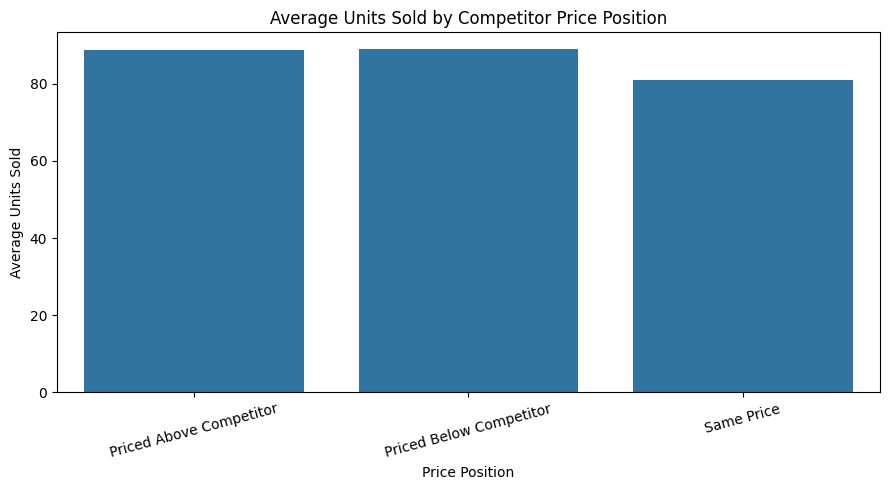

In [96]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=competitor_analysis,
    x="Price Position",
    y="Average_Units_Sold"
)

plt.title("Average Units Sold by Competitor Price Position")
plt.xlabel("Price Position")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [97]:
correlation_columns = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Price",
    "Discount",
    "Competitor Pricing",
    "Demand",
    "Gross Revenue",
    "Net Revenue"
]

correlation_matrix = df_clean[correlation_columns].corr()

correlation_matrix.round(2)

,Inventory Level,Units Sold,Units Ordered,Price,Discount,Competitor Pricing,Demand,Gross Revenue,Net Revenue
Inventory Level,1.00,0.23,-0.03,-0.04,-0.00,-0.03,0.13,0.12,0.12
Units Sold,0.23,1.00,0.43,-0.01,0.18,-0.01,0.83,0.61,0.58
Units Ordered,-0.03,0.43,1.00,0.04,0.17,0.05,0.51,0.31,0.29
Price,-0.04,-0.01,0.04,1.00,-0.09,0.98,-0.02,0.70,0.72
Discount,-0.00,0.18,0.17,-0.09,1.00,-0.09,0.22,0.05,-0.06
Competitor Pricing,-0.03,-0.01,0.05,0.98,-0.09,1.00,-0.02,0.69,0.70
Demand,0.13,0.83,0.51,-0.02,0.22,-0.02,1.00,0.50,0.47
Gross Revenue,0.12,0.61,0.31,0.70,0.05,0.69,0.50,1.00,0.99
Net Revenue,0.12,0.58,0.29,0.72,-0.06,0.70,0.47,0.99,1.00


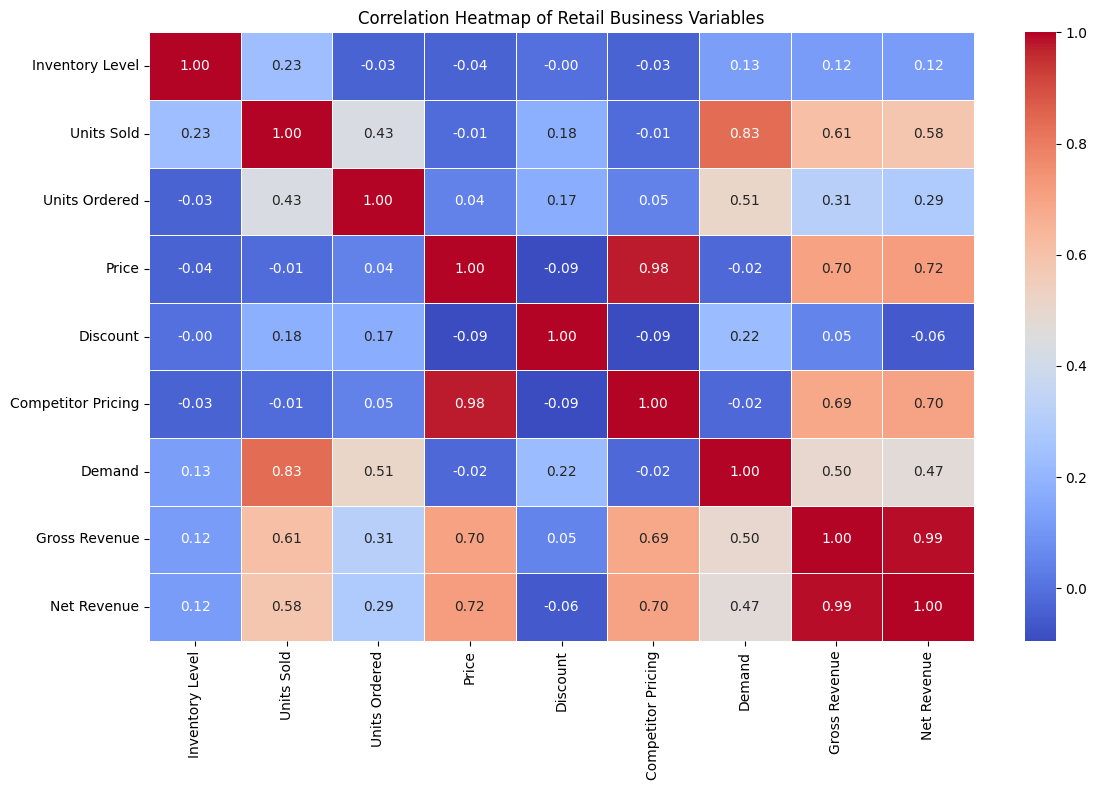

In [98]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Retail Business Variables")
plt.tight_layout()
plt.show()

In [99]:
demand_correlation = (
    correlation_matrix["Demand"]
    .drop("Demand")
    .sort_values(ascending=False)
)

print("Correlation of Business Variables with Demand:")
print(demand_correlation.round(3))

Correlation of Business Variables with Demand:
Units Sold            0.833
Units Ordered         0.512
Gross Revenue         0.498
Net Revenue           0.470
Discount              0.225
Inventory Level       0.127
Competitor Pricing   -0.023
Price                -0.023
Name: Demand, dtype: float64


In [100]:
statistical_columns = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Price",
    "Discount",
    "Demand",
    "Net Revenue"
]

statistical_summary = df_clean[statistical_columns].agg(
    ["mean", "median", "std", "var", "skew", "kurt"]
).T

statistical_summary.round(2)

,mean,median,std,var,skew,kurt
Inventory Level,301.06,227.00,226.51,51306.85,1.59,3.37
Units Sold,88.83,84.00,43.99,1935.52,0.79,1.25
Units Ordered,89.09,0.00,162.40,26375.26,2.52,7.31
Price,67.73,64.50,39.38,1550.62,0.49,-0.48
Discount,9.09,10.00,7.48,55.89,0.64,-0.41
Demand,104.32,100.00,46.96,2205.69,0.61,0.67
Net Revenue,5428.82,4337.61,4302.90,18514920.91,1.50,3.55


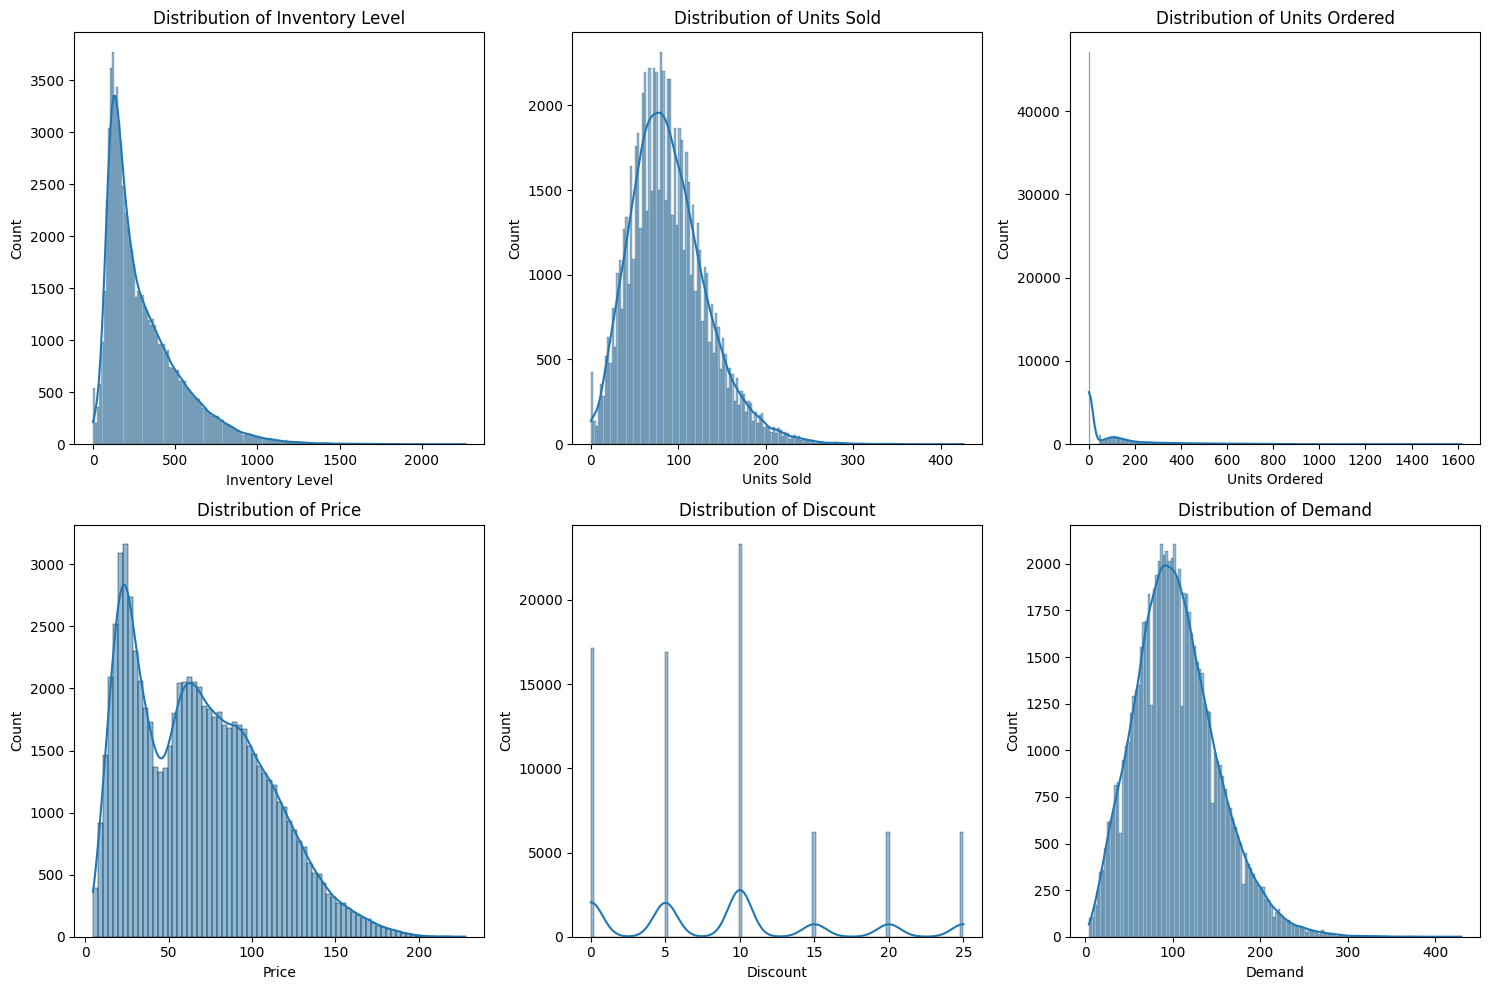

In [101]:
distribution_columns = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Price",
    "Discount",
    "Demand"
]

plt.figure(figsize=(15, 10))

for i, column in enumerate(distribution_columns, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_clean[column], kde=True)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)

plt.tight_layout()
plt.show()

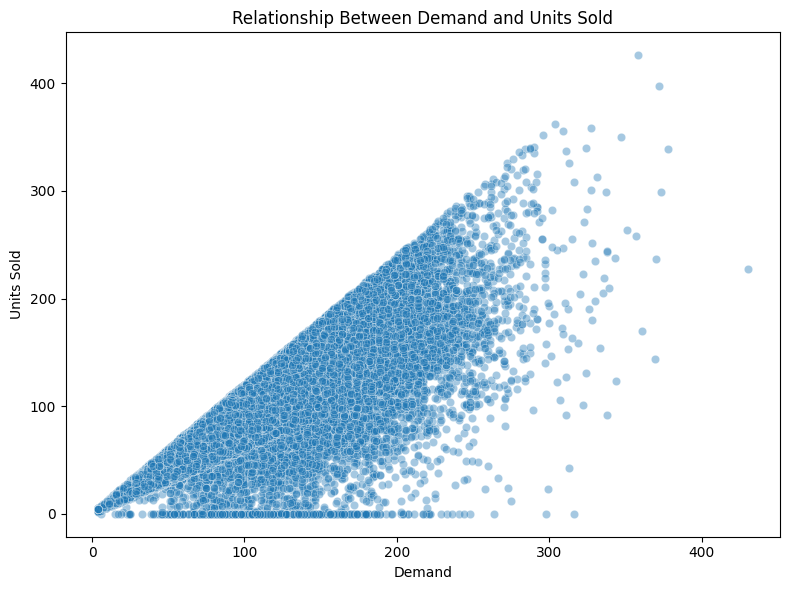

In [102]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_clean,
    x="Demand",
    y="Units Sold",
    alpha=0.4
)

plt.title("Relationship Between Demand and Units Sold")
plt.xlabel("Demand")
plt.ylabel("Units Sold")
plt.tight_layout()
plt.show()

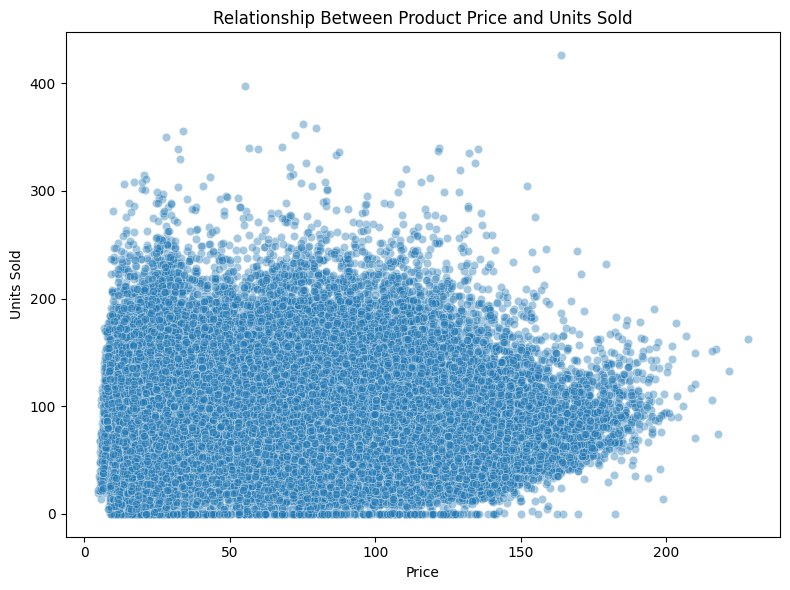

In [103]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_clean,
    x="Price",
    y="Units Sold",
    alpha=0.4
)

plt.title("Relationship Between Product Price and Units Sold")
plt.xlabel("Price")
plt.ylabel("Units Sold")
plt.tight_layout()
plt.show()

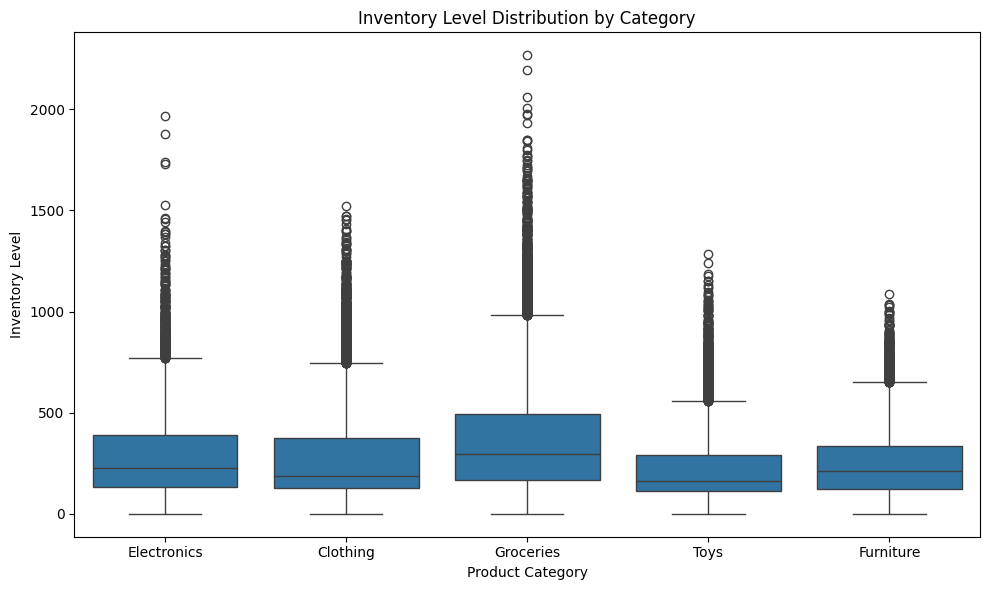

In [104]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x="Category",
    y="Inventory Level"
)

plt.title("Inventory Level Distribution by Category")
plt.xlabel("Product Category")
plt.ylabel("Inventory Level")
plt.tight_layout()
plt.show()

In [105]:
import os

os.makedirs("Retail_Analysis_Report/Charts", exist_ok=True)

In [106]:
plt.savefig(
    "Retail_Analysis_Report/Charts/chart_name.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>